
# 01 — Demographic Analysis: Costa Brava

## Objective
Explore the demographic structure of municipalities in Catalunya to
estimate the size and distribution of the potential older-adult market.

## Research questions
1. Which municipalities have the largest population aged 60 and over?
2. Which municipalities have the highest proportion of residents aged 60 and over?
3. How does the demographic profile vary across municipalities?

## Data source
Idescat — Population by sex and age, year by year (2025).

## Scope and limitations
The geographic scope must be defined explicitly.
Population aged 60 and over is an initial market-size proxy, not evidence
of demand for activities or willingness to pay.


In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")


Libraries imported successfully.
Pandas version: 3.1.0


In [3]:
# Locate the project root independently of the notebook's working directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "censph_10_mun_2025_pc.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Download the Idescat CSV and place it in data/raw/."
    )

df_raw = pd.read_csv(
    DATA_PATH,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print(f"Dataset loaded: {DATA_PATH.name}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

Dataset loaded: censph_10_mun_2025_pc.csv
Shape: 290,088 rows × 7 columns


In [4]:
display(df_raw.head(10))

,año,municipio,edad,sexo,concepto,estado,valor
0,2025,Abella de la Conca,0 años,hombres,población,NaN,0
1,2025,Abella de la Conca,0 años,mujeres,población,NaN,1
2,2025,Abella de la Conca,0 años,total,población,NaN,1
3,2025,Abella de la Conca,1 año,hombres,población,NaN,0
4,2025,Abella de la Conca,1 año,mujeres,población,NaN,1
5,2025,Abella de la Conca,1 año,total,población,NaN,1
6,2025,Abella de la Conca,2 años,hombres,población,NaN,0
7,2025,Abella de la Conca,2 años,mujeres,población,NaN,0
8,2025,Abella de la Conca,2 años,total,población,NaN,0
9,2025,Abella de la Conca,3 años,hombres,población,NaN,1


In [5]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
df_raw.info()

print("\nMissing values:")
display(
    df_raw.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

print("\nNumber of duplicate rows:")
print(df_raw.duplicated().sum())

Column names:
['año', 'municipio', 'edad', 'sexo', 'concepto', 'estado', 'valor']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 290088 entries, 0 to 290087
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   año        290088 non-null  int64  
 1   municipio  290088 non-null  str    
 2   edad       290088 non-null  str    
 3   sexo       290088 non-null  str    
 4   concepto   290088 non-null  str    
 5   estado     0 non-null       float64
 6   valor      290088 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 15.5 MB

Missing values:


,missing_values
estado,290088
municipio,0
año,0
edad,0
sexo,0
concepto,0
valor,0



Number of duplicate rows:
0


In [6]:
print("Dataset dimensions:", df_raw.shape)
print("Unique values per column:")

for column in df_raw.columns:
    print(f"{column}: {df_raw[column].nunique(dropna=True):,}")

Dataset dimensions: (290088, 7)
Unique values per column:
año: 1
municipio: 948
edad: 102
sexo: 3
concepto: 1
estado: 0
valor: 3,437


In [8]:
# Work on a copy of the raw dataset
df = df_raw.copy()

# Remove the completely empty column
df = df.drop(columns=["estado"])

# Keep only the year and concept under study
df = df.loc[
    (df["año"] == 2025)
    & (df["concepto"] == "población")
].copy()

# Extract numeric age from labels such as "92 años"
# The special category "total" will remain missing
df["edad_num"] = pd.to_numeric(
    df["edad"].str.extract(r"^(\d+)")[0],
    errors="coerce"
)

# Table 1: individual ages, with total population by age
df_ages = df.loc[
    (df["sexo"] == "total")
    & (df["edad_num"].notna())
].copy()

df_ages["edad_num"] = df_ages["edad_num"].astype(int)

# Table 2: total population across all ages
df_population_total = df.loc[
    (df["edad"] == "total")
    & (df["sexo"] == "total")
].copy()

# Basic checks
assert df_ages["edad_num"].notna().all()
assert not df_ages.duplicated(["municipio", "edad_num"]).any()
assert not df_population_total.duplicated(["municipio"]).any()

print("Individual-age records:", len(df_ages))
print("Municipal total records:", len(df_population_total))
print("Municipalities in age data:", df_ages["municipio"].nunique())
print("Municipalities in total data:", df_population_total["municipio"].nunique())

display(df_ages.head())
display(df_population_total.head())

Individual-age records: 95748
Municipal total records: 948
Municipalities in age data: 948
Municipalities in total data: 948


,año,municipio,edad,sexo,concepto,valor,edad_num
2,2025,Abella de la Conca,0 años,total,población,1,0
5,2025,Abella de la Conca,1 año,total,población,1,1
8,2025,Abella de la Conca,2 años,total,población,0,2
11,2025,Abella de la Conca,3 años,total,población,1,3
14,2025,Abella de la Conca,4 años,total,población,0,4


,año,municipio,edad,sexo,concepto,valor,edad_num
305,2025,Abella de la Conca,total,total,población,162,NaN
611,2025,Abrera,total,total,población,13207,NaN
917,2025,Àger,total,total,población,635,NaN
1223,2025,Agramunt,total,total,población,5638,NaN
1529,2025,Aguilar de Segarra,total,total,población,293,NaN


In [9]:
# Population aged 60 and over by municipality
population_60_plus = (
    df_ages.loc[df_ages["edad_num"] >= 60]
    .groupby("municipio", as_index=False)["valor"]
    .sum()
    .rename(columns={"valor": "population_60_plus"})
)

# Total population by municipality
population_total = (
    df_population_total[["municipio", "valor"]]
    .rename(columns={"valor": "population_total"})
)

# Merge both tables
municipality_stats = population_total.merge(
    population_60_plus,
    on="municipio",
    how="left",
    validate="one_to_one"
)

municipality_stats["population_60_plus"] = (
    municipality_stats["population_60_plus"].fillna(0)
)

# Calculate the percentage of older residents
municipality_stats["pct_60_plus"] = (
    100 * municipality_stats["population_60_plus"]
    / municipality_stats["population_total"]
)

municipality_stats = municipality_stats.sort_values(
    "population_60_plus",
    ascending=False
)

display(municipality_stats.head(15).round(2))

,municipio,population_total,population_60_plus,pct_60_plus
947,Catalunya,8124126,2106500,25.93
90,Barcelona,1713247,460936,26.90
356,"Hospitalet de Llobregat, l'",292161,70588,24.16
78,Badalona,230642,59881,25.96
643,Sabadell,224589,57424,25.57
815,Terrassa,232676,55958,24.05
385,Lleida,147369,37493,25.44
806,Tarragona,143260,37014,25.84
430,Mataró,131370,33419,25.44
742,Santa Coloma de Gramenet,123250,30590,24.82


In [10]:
# Check whether the sum of individual ages matches the official total
age_sums = (
    df_ages.groupby("municipio")["valor"]
    .sum()
    .rename("sum_individual_ages")
)

validation = population_total.merge(
    age_sums,
    on="municipio",
    how="left",
    validate="one_to_one"
)

validation["difference"] = (
    validation["population_total"]
    - validation["sum_individual_ages"]
)

display(validation.sort_values("difference", ascending=False).head(10))

print("Municipalities with mismatched totals:",
      (validation["difference"] != 0).sum())

,municipio,population_total,sum_individual_ages,difference
0,Abella de la Conca,162,162,0
1,Abrera,13207,13207,0
2,Àger,635,635,0
3,Agramunt,5638,5638,0
4,Aguilar de Segarra,293,293,0
5,Agullana,881,881,0
6,Aiguafreda,2569,2569,0
7,Aiguamúrcia,1002,1002,0
8,Aiguaviva,805,805,0
9,Aitona,2575,2575,0


Municipalities with mismatched totals: 0



## 2. Age Structure and Population Segmentation

### Objective
Understand the age structure of the population and distinguish
between potential user segments.

### Research questions
- What proportion of the population is aged 60 and over?
- How is the older population distributed across age groups?
- Do municipalities differ in their demographic profiles?


In [11]:
# Define age groups for the demographic analysis
age_bins = [0, 18, 40, 60, 75, 85, 101]
age_labels = [
    "0-17",
    "18-39",
    "40-59",
    "60-74",
    "75-84",
    "85+"
]

df_ages["age_group"] = pd.cut(
    df_ages["edad_num"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Aggregate population by age group across Catalonia
age_distribution = (
    df_ages.groupby("age_group", observed=False)["valor"]
    .sum()
    .rename("population")
    .reset_index()
)

total_population = age_distribution["population"].sum()

age_distribution["percentage"] = (
    100 * age_distribution["population"] / total_population
)

display(age_distribution.round(2))

,age_group,population,percentage
0,0-17,2710272,16.68
1,18-39,4346230,26.75
2,40-59,4978750,30.64
3,60-74,2608352,16.05
4,75-84,1113626,6.85
5,85+,491022,3.02


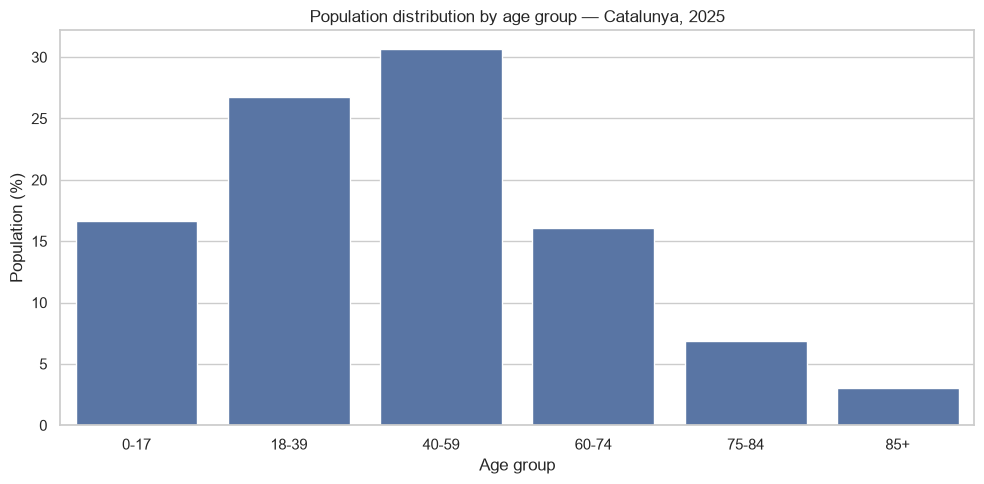

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_distribution,
    x="age_group",
    y="percentage"
)

plt.title("Population distribution by age group — Catalunya, 2025")
plt.xlabel("Age group")
plt.ylabel("Population (%)")
plt.tight_layout()
plt.show()

In [14]:
# Aggregate population by municipality and age group
municipality_age_groups = (
    df_ages.groupby(
        ["municipio", "age_group"],
        observed=False
    )["valor"]
    .sum()
    .unstack(fill_value=0)
)

# Calculate each municipality's total population
municipality_age_groups["population_total"] = (
    municipality_age_groups.sum(axis=1)
)

# Calculate older population and its share
municipality_age_groups["population_60_plus"] = (
    municipality_age_groups[["60-74", "75-84", "85+"]].sum(axis=1)
)

municipality_age_groups["pct_60_plus"] = (
    100 * municipality_age_groups["population_60_plus"]
    / municipality_age_groups["population_total"]
)

# Exclude very small municipalities for this comparison
municipality_comparison = (
    municipality_age_groups
    .loc[municipality_age_groups["population_total"] >= 5_000]
    .sort_values("pct_60_plus", ascending=False)
)

display(
    municipality_comparison[
        ["population_total", "population_60_plus", "pct_60_plus"]
    ].head(20).round(2)
)

age_group,population_total,population_60_plus,pct_60_plus
municipio,,,
Gironella,5082,1691,33.27
Llançà,5033,1654,32.86
"Ametlla de Mar, l'",7436,2393,32.18
Súria,6196,1989,32.10
Ripoll,10812,3459,31.99
Sallent,7043,2237,31.76
Navarcles,6277,1973,31.43
Tremp,6156,1923,31.24
"Escala, l'",10641,3292,30.94


In [ ]:
# Provisional Costa Brava municipality sample
# Names must match the Idescat dataset exactly.

costa_brava_municipalities = [
    "Blanes",
    "Lloret de Mar",
    "Tossa de Mar",
    "Santa Cristina d'Aro",
    "Sant Feliu de Guíxols",
    "Platja d'Aro i s'Agaró",
    "Calonge i Sant Antoni",
    "Palamós",
    "Palafrugell",
    "Mont-ras",
    "Begur",
    "Pals",
    "Torroella de Montgrí",
    "Escala, l'",
    "Sant Pere Pescador",
    "Castelló d'Empúries",
    "Roses",
    "Cadaqués",
    "Port de la Selva",
    "Llançà",
    "Colera",
    "Portbou",
]

# Check which names exist in the dataset
available_names = set(municipality_stats["municipio"])

matched = [
    name for name in costa_brava_municipalities
    if name in available_names
]

missing = [
    name for name in costa_brava_municipalities
    if name not in available_names
]

print(f"Matched municipalities: {len(matched)}")
print(f"Names requiring review: {len(missing)}")
print("Missing names:", missing)

Matched municipalities: 19
Names requiring review: 3
Missing names: ["Castell-Platja d'Aro", "l'Escala", 'El Port de la Selva']
